### Region of interest (ROI) cropping
Crop images to focus on the main object, discarding background margins and artifacts

threshold_val:  51.0


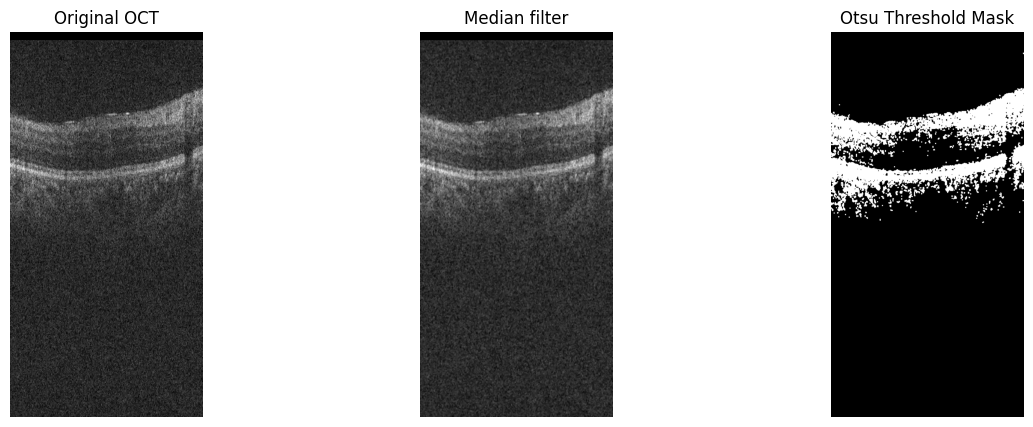

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocess_RESC_image(image_path):
    img_original = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.medianBlur(img_original, 3)
    
    if img is None:
        print("Error: Image not found.")
        return

    # --- Otsu's Thresholding ---
    # This automatically finds the best threshold value to separate background from foreground
    threshold_val, img_otsu = cv2.threshold(
        img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    print("threshold_val: ", threshold_val)

    # Removes small "salt and pepper" noise from the thresholded mask
    kernel = np.ones((3,3), np.uint8)
    img_otsu = cv2.morphologyEx(img_otsu, cv2.MORPH_OPEN, kernel)

    # Visualization
    titles = ['Original OCT', 'Median filter', 'Otsu Threshold Mask']
    images = [img_original, img, img_otsu]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images[i], 'gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

    return img_otsu

# Usage
mask = preprocess_RESC_image("/media/vhondru/hdd/istoian/BMAD/dataset/RESC/train/good/3.png")

In [4]:
mask

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1024, 512), dtype=uint8)

In [2]:
from src.utils.preprocessing import get_image_background_borders

(1024, 512)
threshold_val:  51.0


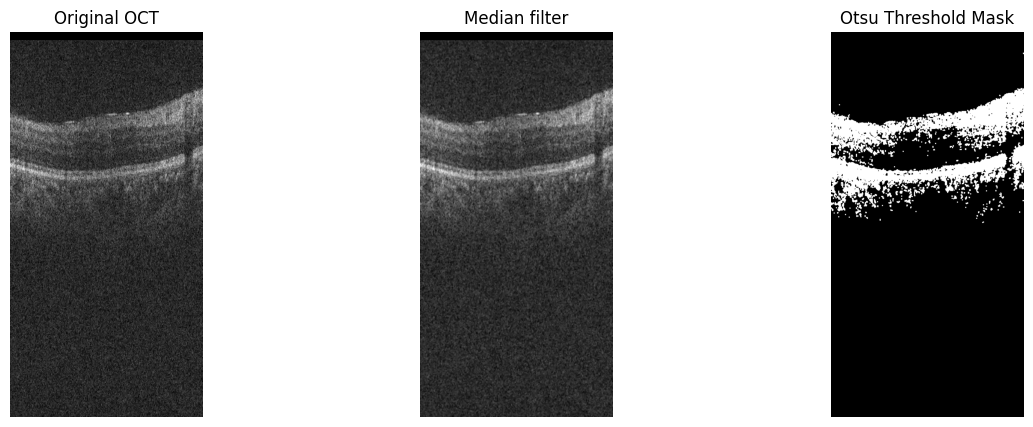

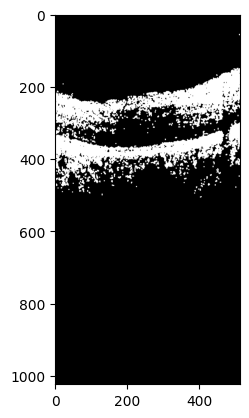

In [ ]:
from PIL import Image

img_path = "/media/vhondru/hdd/istoian/BMAD/dataset/RESC/train/good/3.png"
image = Image.open(img_path).convert("L")
image_arr = np.array(image)
print(image_arr.shape)
preprocessed_img = preprocess_RESC_image(img_path)
plt.imshow(preprocessed_img, "gray")
borders_dict = get_image_background_borders(image_arr=preprocessed_img, count_border_pixels=10)
image = image.crop(box=(borders_dict["left"], borders_dict["top"], borders_dict["right"], borders_dict["bottom"]))

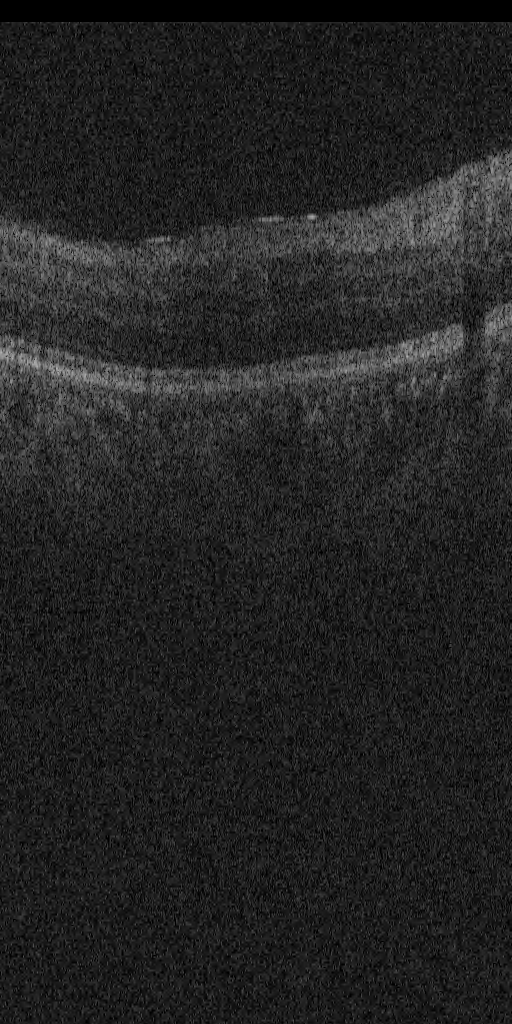